# Проект: Линейные модели в машинном обучении для предприятия "Вольный луг"

Компания "Вольный луг" собирается приобретать коров, но поставщики дают неполную информацию о своих коровах, из за чего основной целью данного проекта является обучение линейных моделей для уточнения свойств коров, которые интересуют фермера(удой и вкусное ли молоко). Нам даны три таблицы: в первой содержится информация о имеющихся у фермера коровах, во второй содержится информация о папе каждой коровы в стаде фермера, а в третьей содержится информация о коровах на продажу. Начнем проект, с загрузки данных, далее идет преобработка, затем исследовательский и корреляционный анализ данных, обучение моделей линейной регрессии и логистичской регрессии и итоговые выводы. Модели линейной регрессии будут использоваться для предсказания удоя у коров, а модели логистической регрессии для предсказания будет ли молоко вкусным.

## Загрузка данных

Подгружаем требуемые библиотеки

In [45]:
!pip install scikit-learn==1.1.3 -q

In [46]:
!pip install phik -q

In [78]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import (LinearRegression, LogisticRegression)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (OneHotEncoder, StandardScaler)
from sklearn.metrics import (r2_score, precision_score, recall_score, mean_absolute_error, mean_squared_error, confusion_matrix)
from phik import phik_matrix

Теперь пора считать данные

In [4]:
df_ferma = pd.read_csv('/datasets/ferma_main.csv',sep=';')
df_dad = pd.read_csv('/datasets/ferma_dad.csv',sep=';')
df_buy = pd.read_csv('/datasets/cow_buy.csv',sep=';')

Изучим первый датафрейм

In [5]:
df_ferma.info()
display(df_ferma.head(5))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 634 entries, 0 to 633
Data columns (total 12 columns):
 #   Column                                 Non-Null Count  Dtype 
---  ------                                 --------------  ----- 
 0   id                                     634 non-null    int64 
 1   Удой, кг                               634 non-null    int64 
 2   ЭКЕ (Энергетическая кормовая единица)  634 non-null    object
 3   Сырой протеин, г                       634 non-null    int64 
 4   СПО (Сахаро-протеиновое соотношение)   634 non-null    object
 5   Порода                                 634 non-null    object
 6   Тип пастбища                           634 non-null    object
 7   порода папы_быка                       634 non-null    object
 8   Жирность,%                             634 non-null    object
 9   Белок,%                                634 non-null    object
 10  Вкус молока                            634 non-null    object
 11  Возраст            

,id,"Удой, кг",ЭКЕ (Энергетическая кормовая единица),"Сырой протеин, г",СПО (Сахаро-протеиновое соотношение),Порода,Тип пастбища,порода папы_быка,"Жирность,%","Белок,%",Вкус молока,Возраст
0,1,5863,"14,2",1743,"0,89",Вис Бик Айдиал,Равнинное,Айдиал,"3,58","3,076",вкусно,более_2_лет
1,2,5529,"12,8",2138,"0,89",Вис Бик Айдиал,Равнинные,Соверин,"3,54","3,079",вкусно,менее_2_лет
2,3,5810,14,1854,"0,885",РефлешнСоверинг,Холмистое,Соверин,"3,59","3,074",не вкусно,более_2_лет
3,4,5895,"12,4",2012,"0,885",РефлешнСоверинг,Холмистое,Айдиал,"3,4","3,075",не вкусно,более_2_лет
4,5,5302,"12,8",1675,"0,885",Вис Бик Айдиал,Равнинные,Соверин,"3,73","3,073",вкусно,менее_2_лет


Изучим второй датафрейм

In [6]:
df_dad.info()
display(df_dad.head(5))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 629 entries, 0 to 628
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   id        629 non-null    int64 
 1   Имя Папы  629 non-null    object
dtypes: int64(1), object(1)
memory usage: 10.0+ KB


,id,Имя Папы
0,1,Буйный
1,2,Соловчик
2,3,Барин
3,4,Буйный
4,5,Барин


Изучим третий датафрейм

In [7]:
df_buy.info()
display(df_buy.head(5))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Порода                   20 non-null     object
 1   Тип пастбища             20 non-null     object
 2   порода папы_быка         20 non-null     object
 3   Имя_папы                 20 non-null     object
 4   Текущая_жирность,%       20 non-null     object
 5   Текущий_уровень_белок,%  20 non-null     object
 6   Возраст                  20 non-null     object
dtypes: object(7)
memory usage: 1.2+ KB


,Порода,Тип пастбища,порода папы_быка,Имя_папы,"Текущая_жирность,%","Текущий_уровень_белок,%",Возраст
0,Вис Бик Айдиал,холмистое,Айдиал,Геркулес,"3,58","3,076",более_2_лет
1,Вис Бик Айдиал,равнинное,Соверин,Буйный,"3,54","3,081",менее_2_лет
2,РефлешнСоверинг,равнинное,Соверин,Барин,"3,59","3,074",более_2_лет
3,РефлешнСоверинг,холмистое,Айдиал,Буйный,"3,4","3,061",более_2_лет
4,РефлешнСоверинг,равнинное,Айдиал,Буйный,"3,64","3,074",более_2_лет


##  Предобработка данных

Мы считали данные, теперь время провести первичную предобработку данных:

Начнем с того, что приведем столбцы к нужному типу данных, на прошлом шаге было обнаружено много столбцов, где должен быть float тип данных, а вместо этого там находится object, поэтому на данном этапе мы разберемся со всеми такими стобцами

In [8]:
def convert_to_float(column):
    return pd.to_numeric(column.astype(str).str.replace(',', '.'), errors='coerce')


df_buy['Текущая_жирность,%'] = convert_to_float(df_buy['Текущая_жирность,%'])
df_buy['Текущий_уровень_белок,%'] = convert_to_float(df_buy['Текущий_уровень_белок,%'])


df_ferma['ЭКЕ (Энергетическая кормовая единица)'] = convert_to_float(df_ferma['ЭКЕ (Энергетическая кормовая единица)'])
df_ferma['СПО (Сахаро-протеиновое соотношение)'] = convert_to_float(df_ferma['СПО (Сахаро-протеиновое соотношение)'])
df_ferma['Жирность,%'] = convert_to_float(df_ferma['Жирность,%'])
df_ferma['Белок,%'] = convert_to_float(df_ferma['Белок,%'])


df_ferma.info()
df_buy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 634 entries, 0 to 633
Data columns (total 12 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   id                                     634 non-null    int64  
 1   Удой, кг                               634 non-null    int64  
 2   ЭКЕ (Энергетическая кормовая единица)  634 non-null    float64
 3   Сырой протеин, г                       634 non-null    int64  
 4   СПО (Сахаро-протеиновое соотношение)   634 non-null    float64
 5   Порода                                 634 non-null    object 
 6   Тип пастбища                           634 non-null    object 
 7   порода папы_быка                       634 non-null    object 
 8   Жирность,%                             634 non-null    float64
 9   Белок,%                                634 non-null    float64
 10  Вкус молока                            634 non-null    object 
 11  Возрас

Далее разберемся с пропусками

In [9]:
display(df_ferma.isna().sum())
display(df_buy.isna().sum())
display(df_dad.isna().sum())

id                                       0
Удой, кг                                 0
ЭКЕ (Энергетическая кормовая единица)    0
Сырой протеин, г                         0
СПО (Сахаро-протеиновое соотношение)     0
Порода                                   0
Тип пастбища                             0
порода папы_быка                         0
Жирность,%                               0
Белок,%                                  0
Вкус молока                              0
Возраст                                  0
dtype: int64

Порода                     0
Тип пастбища               0
порода папы_быка           0
Имя_папы                   0
Текущая_жирность,%         0
Текущий_уровень_белок,%    0
Возраст                    0
dtype: int64

id          0
Имя Папы    0
dtype: int64

Все выглядит хорошо, тогда перейдем к дубликатам. Убирать дубликаты в листе коров на продажу не будем, так как в силу малого числа коров, можно предположить, что в ней нет дубликатов

In [10]:
print('Дубликаты до обработки:',df_ferma.duplicated().sum(),df_dad.duplicated().sum())
df_ferma = df_ferma.drop_duplicates()
df_dad = df_dad.drop_duplicates()
print('Дубликаты после обработки:',df_ferma.duplicated().sum(),df_dad.duplicated().sum())

Дубликаты до обработки: 5 0
Дубликаты после обработки: 0 0


Также присутствуют неявные дубликаты в столбцах с породой и пастбищем, в таблице с данными коров из стада фермера

In [11]:
df_ferma['Тип пастбища'] = df_ferma['Тип пастбища'].str.replace('равнинное','Равнинное')
df_ferma['Тип пастбища'] = df_ferma['Тип пастбища'].str.replace('Равнинные','Равнинное')
df_ferma['порода папы_быка'] = df_ferma['порода папы_быка'].str.replace('Айдиалл','Айдиал')
df_buy['Тип пастбища'] = df_buy['Тип пастбища'].str.replace('холмистое','Холмистое')
df_buy['Тип пастбища'] = df_buy['Тип пастбища'].str.replace('равнинное','Равнинное')

В данном этапе мы привели столбцы к правильному типу данных. Далее мы провели поиск пропусков и не нашли ни одного, после чего начали искать дубликаты, было найдено и устранено несколько явных и некоторое количество неявных, в некоторых таблицах отличался регистр, что мы и исправили.

## Исследовательский анализ данных

Начнем с того, что визуализируем количественные и качественные признаки для дальнейшего анализа

Количественные признаки коров в стаде фермера


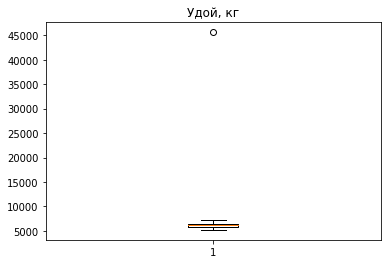

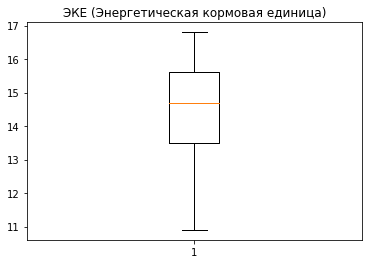

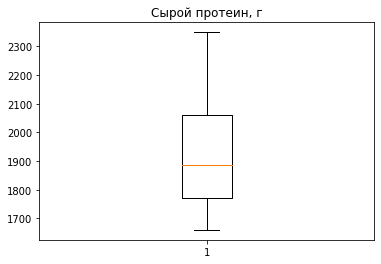

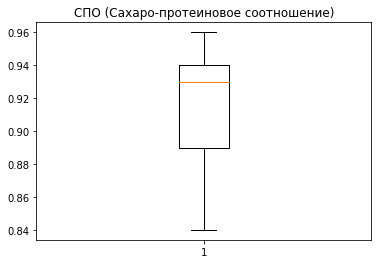

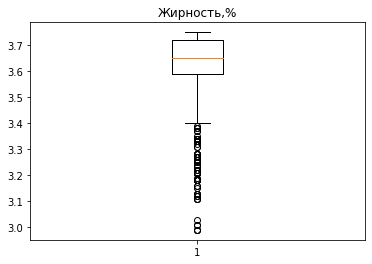

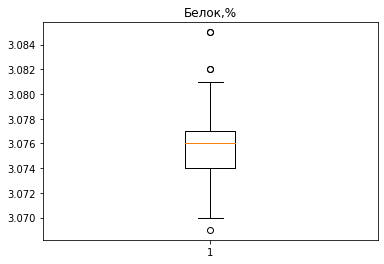

Количественные признаки коров на продажу


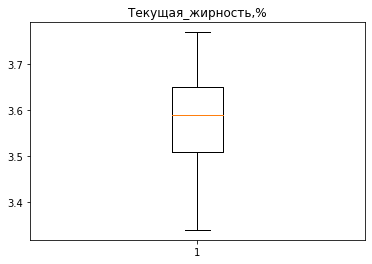

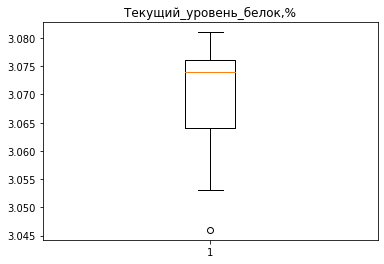

In [12]:
df_ferma_num_col = ['Удой, кг',
                         'ЭКЕ (Энергетическая кормовая единица)',
                         'Сырой протеин, г',
                         'СПО (Сахаро-протеиновое соотношение)',
                         'Жирность,%',
                         'Белок,%']
df_buy_num_col = ['Текущая_жирность,%','Текущий_уровень_белок,%']

print("Количественные признаки коров в стаде фермера")
for i in df_ferma_num_col:
    plt.title(i)
    plt.boxplot(df_ferma[i])
    plt.show()

print("Количественные признаки коров на продажу")
for i in df_buy_num_col:
    plt.title(i)
    plt.boxplot(df_buy[i])
    plt.show()

В столбце с жирностью слишком много выбросов, они составляют большую часть данных, поэтому их обрабатывать не следует

In [13]:
df_ferma = df_ferma[df_ferma['Удой, кг']<10000]
df_ferma = df_ferma[df_ferma['Белок,%']>3.070]
df_ferma = df_ferma[df_ferma['Белок,%']<3.082]
df_buy = df_buy[df_buy['Текущий_уровень_белок,%']>3.050]


Количественные признаки коров в стаде фермера


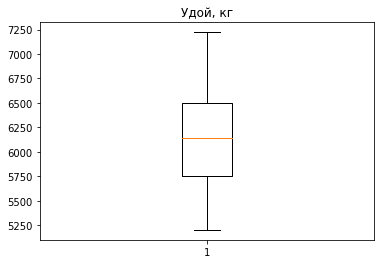

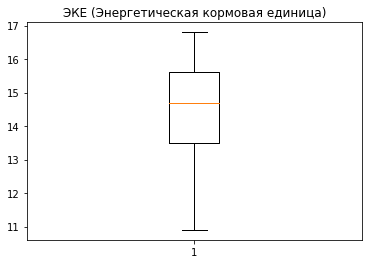

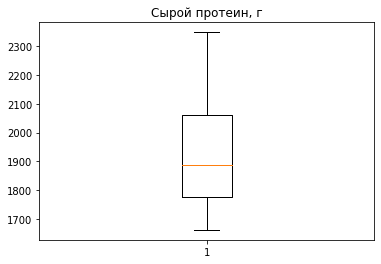

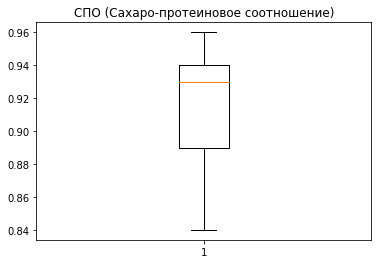

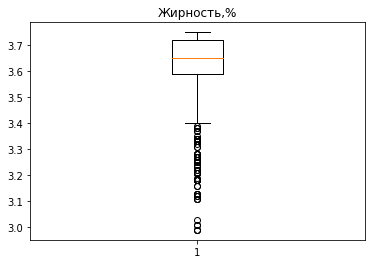

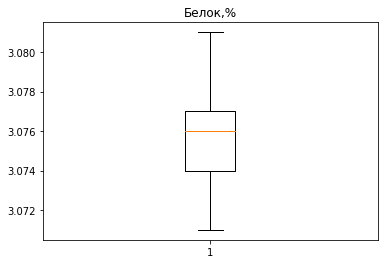

Количественные признаки коров на продажу


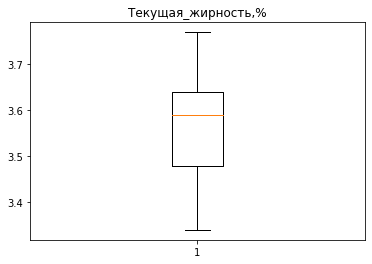

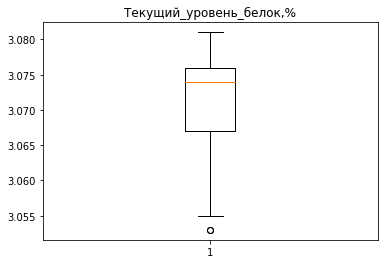

In [14]:
print("Количественные признаки коров в стаде фермера")
for i in df_ferma_num_col:
    plt.title(i)
    plt.boxplot(df_ferma[i])
    plt.show()

print("Количественные признаки коров на продажу")
for i in df_buy_num_col:
    plt.title(i)
    plt.boxplot(df_buy[i])
    plt.show()

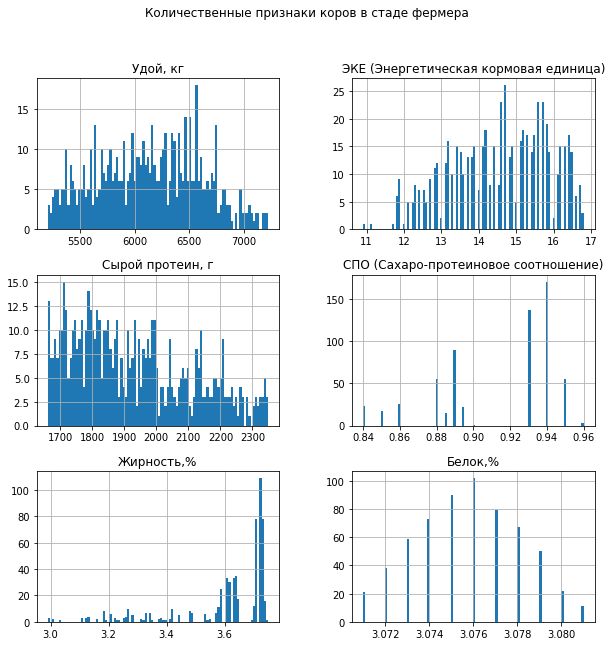

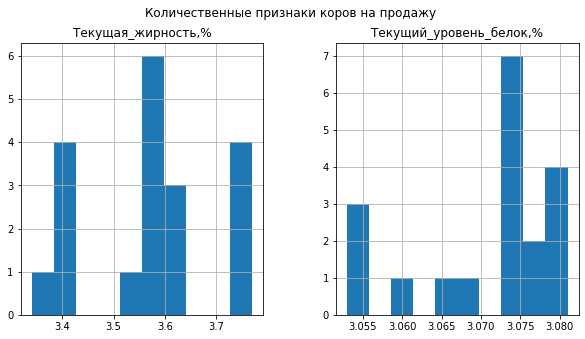

In [15]:
df_ferma[df_ferma_num_col].hist(figsize=(10,10),bins=100)
plt.suptitle("Количественные признаки коров в стаде фермера")
plt.show()

df_buy[df_buy_num_col].hist(figsize=(10,5),bins=10)
plt.suptitle("Количественные признаки коров на продажу")
plt.show()

Были построены диаграммы размаха, были замечены выбросы в некоторых столбцах, поэтому мы их удалили. В остальном большая часть параметров имеет близкое к нормальному распределение кроме жирности и отношения сахара к протеину, данные столбцы имеют структуру в виде нескольких пиков, с большими пробелами. В данных с коровами на продажу не видно нормального распределения, но это происходит в силу того, что данных мало

Качественные признаки коров в стаде фермера


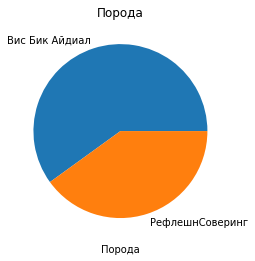

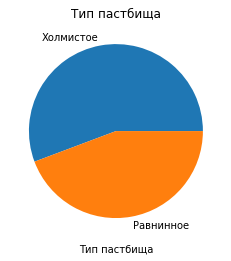

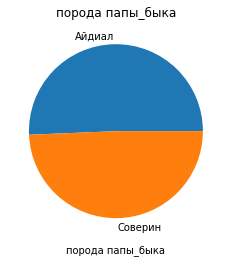

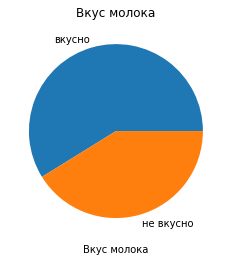

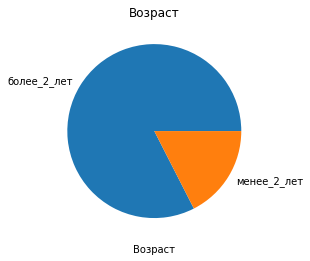

Качественные признаки коров на продажу


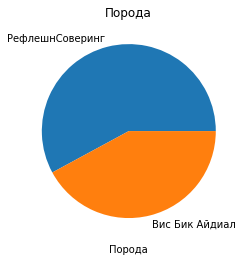

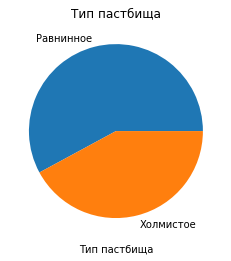

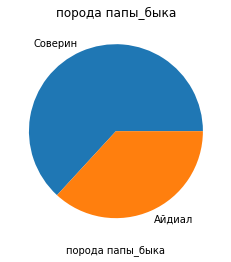

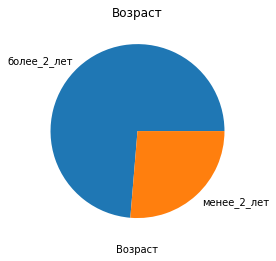

Имена отцов в стаде фермера


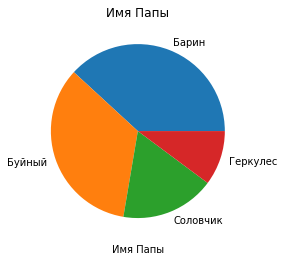

In [16]:
df_ferma_feat = df_ferma[['Порода',
                         'Тип пастбища',
                         'порода папы_быка',
                         'Вкус молока',
                         'Возраст']]
df_buy_feat = df_buy[['Порода',
                      'Тип пастбища',
                      'порода папы_быка',
                      'Возраст']]
print("Качественные признаки коров в стаде фермера")
for i in df_ferma_feat.columns:
    plt.pie(df_ferma_feat[i].value_counts().values,labels=df_ferma_feat[i].value_counts().index)
    plt.xlabel(i) 
    plt.title(i)
    plt.show()

print("Качественные признаки коров на продажу")
for i in df_buy_feat.columns:
    plt.pie(df_buy_feat[i].value_counts().values,labels=df_buy_feat[i].value_counts().index)
    plt.xlabel(i) 
    plt.title(i)
    plt.show()

print("Имена отцов в стаде фермера")
plt.pie(df_dad['Имя Папы'].value_counts().values, labels=df_dad['Имя Папы'].value_counts().index)
plt.xlabel('Имя Папы')
plt.title('Имя Папы')
plt.show()


По визуализации качественных параметров можно сделать вывод, что в стаде у фермера преобладает порода "Вис Бик Айдиал", на продаже распределение пород равное, но порода папы быка имеет обратную тенденцию, в продаже преобладает Соверин, а в стаде фермера породы распределены поровну, также еще одно важное отличие это то, что в обеих таблицах преобладают коровы возраста более двух лет, но по понятным причинам в стаде фермера концентрация более возрастных коров намного выше

По итогу можно сказать, что распределения количественных признаков в большинстве имеют близкое к нормальное распределение, за исключением столбца с жирностью и СПО. В категориальных значениях все категории предствлены в реалистичном соотношении и нет категорий, которые представлены в слишком маленьком числе 

## Корреляционный анализ

In [52]:
df_ferma.drop('id',axis=1).phik_matrix(interval_cols=df_ferma_num_col)

,"Удой, кг",ЭКЕ (Энергетическая кормовая единица),"Сырой протеин, г",СПО (Сахаро-протеиновое соотношение),Порода,Тип пастбища,порода папы_быка,"Жирность,%","Белок,%",Вкус молока,Возраст,СПО,ЭКЕ квадрат,Имя Папы
"Удой, кг",1.000000,0.724821,0.465054,0.661650,0.167285,0.282342,0.519024,0.705606,0.224759,0.172151,0.997994,0.999944,0.686827,0.436710
ЭКЕ (Энергетическая кормовая единица),0.724821,1.000000,0.456337,0.595619,0.126093,0.081037,0.191533,0.720423,0.000000,0.274289,0.779398,0.906647,1.000000,0.095150
"Сырой протеин, г",0.465054,0.456337,1.000000,0.384769,0.089039,0.068732,0.000000,0.399326,0.226257,0.171776,0.349968,0.531349,0.346932,0.093807
СПО (Сахаро-протеиновое соотношение),0.661650,0.595619,0.384769,1.000000,0.064184,0.135072,0.416350,0.640556,0.000000,0.565055,0.751130,1.000000,0.694120,0.403605
Порода,0.167285,0.126093,0.089039,0.064184,1.000000,0.210632,0.078016,0.221920,0.344997,0.000000,0.060028,0.046700,0.109015,0.379490
Тип пастбища,0.282342,0.081037,0.068732,0.135072,0.210632,1.000000,0.000000,0.000000,0.178817,0.272078,0.121945,0.122591,0.095794,0.234873
порода папы_быка,0.519024,0.191533,0.000000,0.416350,0.078016,0.000000,1.000000,0.000000,0.095554,0.000000,0.348091,0.398576,0.103648,0.983771
"Жирность,%",0.705606,0.720423,0.399326,0.640556,0.221920,0.000000,0.000000,1.000000,0.000000,0.201388,0.682415,0.920570,0.764007,0.096106
"Белок,%",0.224759,0.000000,0.226257,0.000000,0.344997,0.178817,0.095554,0.000000,1.000000,0.112676,0.000000,0.000000,0.000000,0.111752
Вкус молока,0.172151,0.274289,0.171776,0.565055,0.000000,0.272078,0.000000,0.201388,0.112676,1.000000,0.158048,0.107979,0.256083,0.000000


Исходя из таблицы коллинераности, можно сказать, что столбцы с СПО, возрастом и жирностью имеют мультиколлинеарность

In [53]:
df_buy.phik_matrix(interval_cols=df_buy_num_col)

/opt/conda/lib/python3.9/site-packages/phik/data_quality.py:82: UserWarning: Not enough unique value for variable СПО for analysis 1. Dropping this column
  warnings.warn(
/opt/conda/lib/python3.9/site-packages/phik/data_quality.py:82: UserWarning: Not enough unique value for variable Сырой протеин, г for analysis 1. Dropping this column
  warnings.warn(
/opt/conda/lib/python3.9/site-packages/phik/data_quality.py:82: UserWarning: Not enough unique value for variable ЭКЕ квадрат for analysis 1. Dropping this column
  warnings.warn(


,Порода,Тип пастбища,порода папы_быка,Имя Папы,"Жирность,%","Текущий_уровень_белок,%",Возраст,"Удой, кг"
Порода,1.000000,0.135185,0.000000,0.209302,0.835624,0.495347,0.00000,1.000000
Тип пастбища,0.135185,1.000000,0.400222,0.209302,0.835624,0.421106,0.00000,1.000000
порода папы_быка,0.000000,0.400222,1.000000,0.603675,1.000000,0.493015,0.00000,1.000000
Имя Папы,0.209302,0.209302,0.603675,1.000000,0.911494,0.543950,0.00000,1.000000
"Жирность,%",0.835624,0.835624,1.000000,0.911494,1.000000,0.789700,0.79426,1.000000
"Текущий_уровень_белок,%",0.495347,0.421106,0.493015,0.543950,0.789700,1.000000,0.00000,0.868051
Возраст,0.000000,0.000000,0.000000,0.000000,0.794260,0.000000,1.00000,1.000000
"Удой, кг",1.000000,1.000000,1.000000,1.000000,1.000000,0.868051,1.00000,1.000000


В таблице с листом продажи коров мы тоже имеем мультиколлинеарность в столбце с жирностью молока

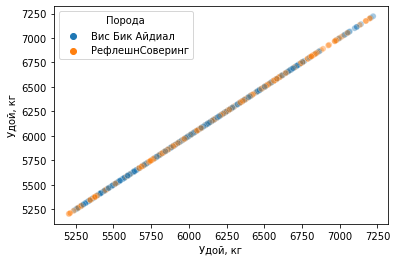

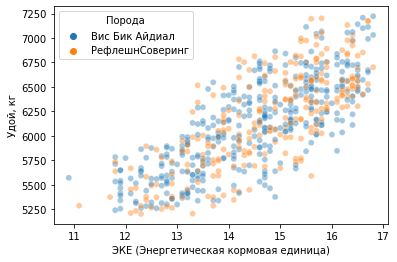

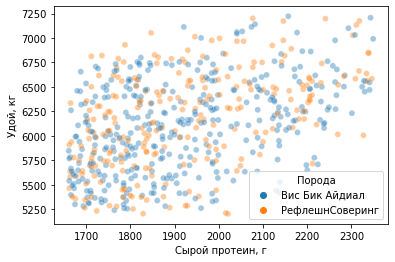

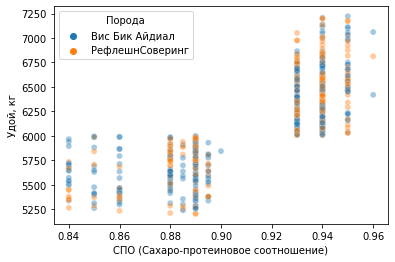

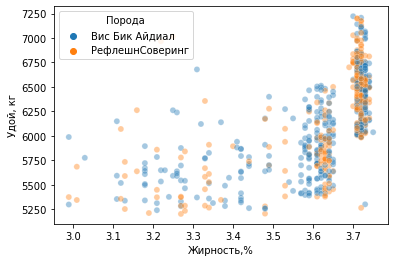

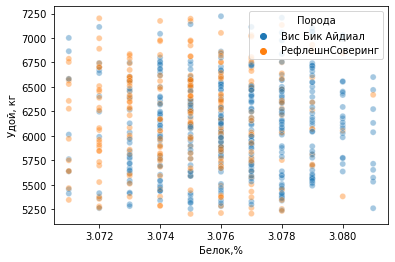

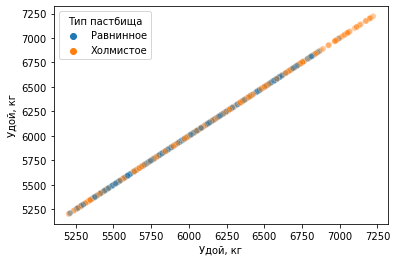

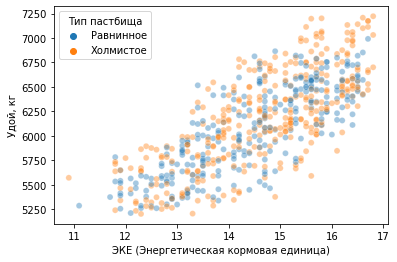

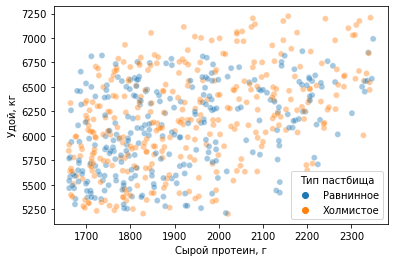

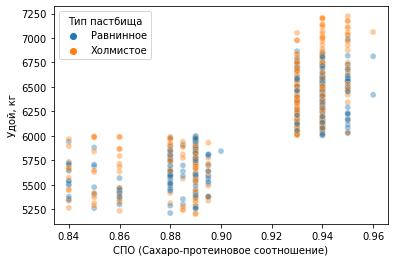

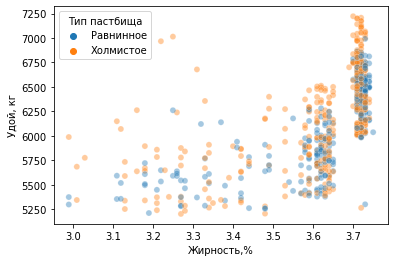

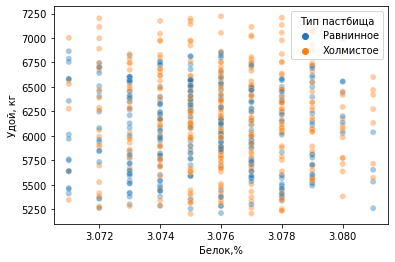

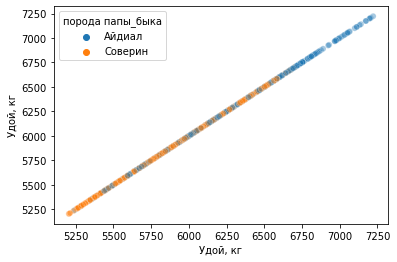

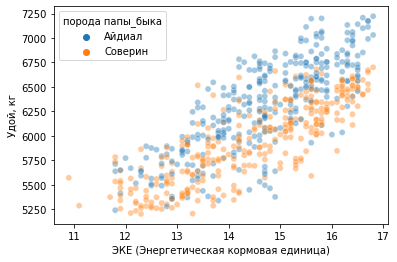

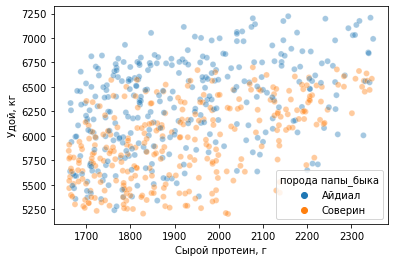

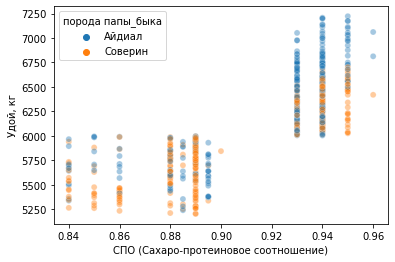

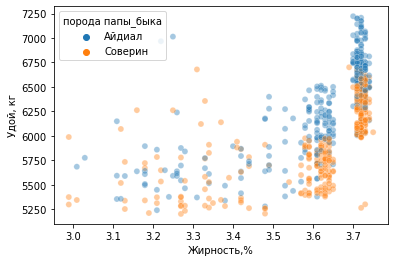

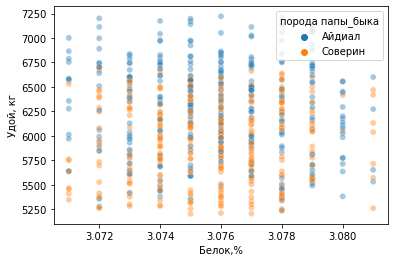

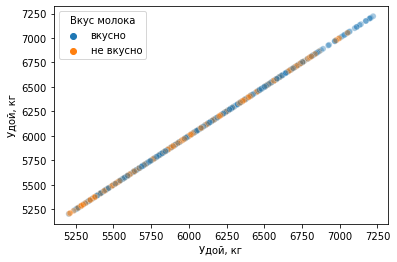

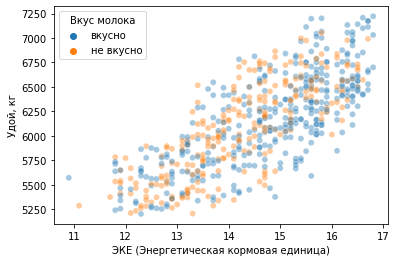

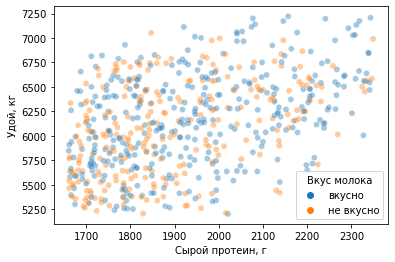

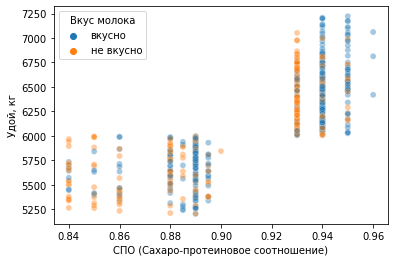

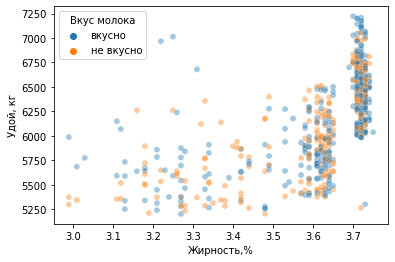

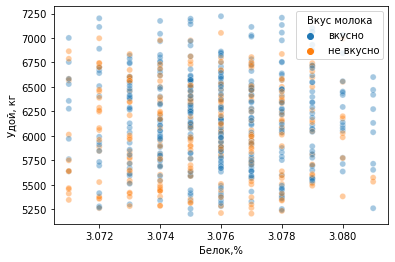

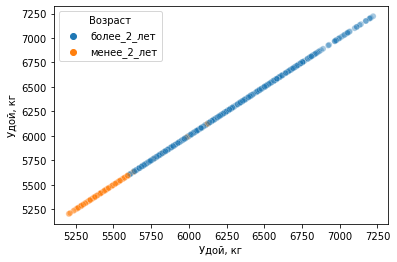

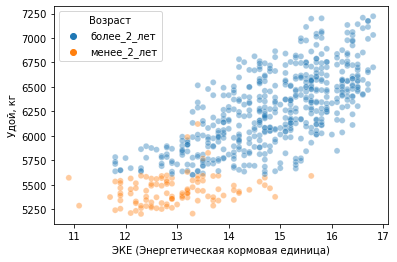

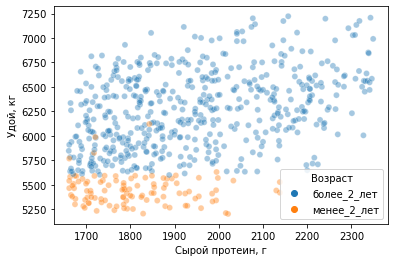

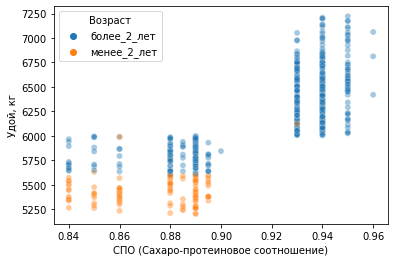

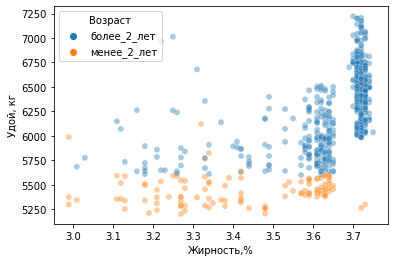

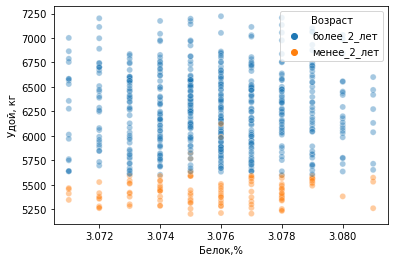

In [19]:
for i in df_ferma_feat.columns:
    for j in df_ferma_num_col:
        sns.scatterplot(x=j,y ='Удой, кг',data=df_ferma,hue=i,alpha=0.4)
        plt.show()


Сырой протеин имеет слабую линейную зависимость. ЭКЕ же имеет довольно сильную квадратичную, жирность и СПО имеют квадратичную с тендецией к кластеризации, белок имеет слабую зависимость с тенденцией к кластеризации.

## Обучение модели линейной регрессии

Нашим целевым признаком является удой. Начнем обучение модели с того, что сделаем переменные с входными и целевым признаками, из таблицы с входными признаками выкинем id и содержание белка, потому что они имеют низкую корреляцию с целевым признаком. Далее требуется отмасштабировать данные и декодировать их для дальнейшего обучения

In [54]:
x1 = df_ferma.drop(['Удой, кг','id','Белок,%','Жирность,%'], axis=1)
y1 = df_ferma['Удой, кг']
cat_col_names = ['Порода','Тип пастбища','порода папы_быка','Возраст']
num_col_names = ['ЭКЕ (Энергетическая кормовая единица)','Сырой протеин, г','СПО (Сахаро-протеиновое соотношение)']
x_train1,x_test1,y_train1,y_test1 = train_test_split(x1,y1,random_state=42)
encoder1 = OneHotEncoder(sparse=False,drop='first')
scaler1 = StandardScaler()
model_lr1 = LinearRegression()

x_train_ohe = encoder1.fit_transform(x_train1[cat_col_names])
x_train_scale = scaler1.fit_transform(x_train1[num_col_names])
x_train_ohe = pd.DataFrame(x_train_ohe,columns=encoder1.get_feature_names())
x_train_scale = pd.DataFrame(x_train_scale,columns=num_col_names)

x_test_ohe = encoder1.fit_transform(x_test1[cat_col_names])
x_test_scale = scaler1.fit_transform(x_test1[num_col_names])
x_test_ohe = pd.DataFrame(x_test_ohe,columns=encoder1.get_feature_names())
x_test_scale = pd.DataFrame(x_test_scale,columns=num_col_names)

x_train1 = x_train_scale.join(x_train_ohe)
x_test1 = x_test_scale.join(x_test_ohe)


/opt/conda/lib/python3.9/site-packages/sklearn/utils/deprecation.py:87: FutureWarning: Function get_feature_names is deprecated; get_feature_names is deprecated in 1.0 and will be removed in 1.2. Please use get_feature_names_out instead.
  warnings.warn(msg, category=FutureWarning)
/opt/conda/lib/python3.9/site-packages/sklearn/utils/deprecation.py:87: FutureWarning: Function get_feature_names is deprecated; get_feature_names is deprecated in 1.0 and will be removed in 1.2. Please use get_feature_names_out instead.
  warnings.warn(msg, category=FutureWarning)


Теперь когда мы подготовили данные к обучению модели можно приступать к самому процессу обучения на треннировочной выборке

In [56]:
model_lr1.fit(x_train1,y_train1)

LinearRegression()

Протестируем нашу модель и оценим ее качество с помощью метрик и анализа остатков

r2 score 0.8008704589520945


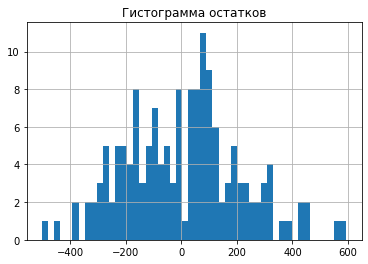

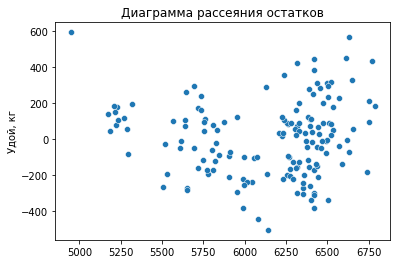

In [57]:
y_pred1 = model_lr1.predict(x_test1)
r2 = r2_score(y_test1,y_pred1)
print('r2 score',r2)
errors1 = y_test1 - y_pred1

errors1.hist(bins=50)
plt.title('Гистограмма остатков')
plt.show()

sns.scatterplot(x=y_pred1,y=errors1)
plt.title('Диаграмма рассеяния остатков')
plt.show()

r2=0.8008704589520945, в принципе неплохая точность, но можно и лучше, на гистограмме распределения остатков видно, что распределение близко к нормальному, но все довольно прерывисто, очень большие перепады. Также была построена диаграмма рассеяния остатков по не видно, что дисперсия остатков увеличивается, когда предсказание затрагивает удой более 6000 кг, то есть именно в той зоне, что нас интересует

Пришло время обучить вторую модель, отличие состоит в том, что мы уберем нелинейную зависимость между входными признаками и целевым, в частности речь идет о столбце ЭКЕ и СПО, в первом случае требуется создать новый столбец, где значение из столбца ЭКЕ будет возведено в квадрат, во втором случае мы сделаем из столбца СПО категориальный бинарный столбец

In [58]:
def EKE_square(row):
    value = row['ЭКЕ (Энергетическая кормовая единица)']**2
    return value

def SPO_cat(row):
    if row['СПО (Сахаро-протеиновое соотношение)']>0.92:
        return 1
    else:
        return 0

df_ferma['СПО'] = df_ferma.apply(SPO_cat,axis=1)
df_ferma['ЭКЕ квадрат'] = df_ferma.apply(EKE_square,axis=1)
display(df_ferma.head(5))

,id,"Удой, кг",ЭКЕ (Энергетическая кормовая единица),"Сырой протеин, г",СПО (Сахаро-протеиновое соотношение),Порода,Тип пастбища,порода папы_быка,"Жирность,%","Белок,%",Вкус молока,Возраст,СПО,ЭКЕ квадрат,Имя Папы
0,1,5863,14.2,1743,0.890,Вис Бик Айдиал,Равнинное,Айдиал,3.58,3.076,вкусно,более_2_лет,0,201.64,Буйный
1,2,5529,12.8,2138,0.890,Вис Бик Айдиал,Равнинное,Соверин,3.54,3.079,вкусно,менее_2_лет,0,163.84,Соловчик
2,3,5810,14.0,1854,0.885,РефлешнСоверинг,Холмистое,Соверин,3.59,3.074,не вкусно,более_2_лет,0,196.00,Барин
3,4,5895,12.4,2012,0.885,РефлешнСоверинг,Холмистое,Айдиал,3.40,3.075,не вкусно,более_2_лет,0,153.76,Буйный
4,5,5302,12.8,1675,0.885,Вис Бик Айдиал,Равнинное,Соверин,3.73,3.073,вкусно,менее_2_лет,0,163.84,Барин


In [59]:
x2 = df_ferma.drop(['Удой, кг','id','Белок,%','Жирность,%'], axis=1)
y2 = df_ferma['Удой, кг']
cat_col_names = ['Порода','Тип пастбища','порода папы_быка','Возраст','СПО']
num_col_names = ['ЭКЕ квадрат','Сырой протеин, г']
x_train2,x_test2,y_train2,y_test2 = train_test_split(x2,y2,random_state=42)
encoder2 = OneHotEncoder(sparse=False,drop='first')
scaler2 = StandardScaler()
model_lr2 = LinearRegression()

x_train_ohe = encoder2.fit_transform(x_train2[cat_col_names])
x_train_scale = scaler2.fit_transform(x_train2[num_col_names])
x_train_ohe = pd.DataFrame(x_train_ohe,columns=encoder2.get_feature_names())
x_train_scale = pd.DataFrame(x_train_scale,columns=num_col_names)

x_test_ohe = encoder2.fit_transform(x_test2[cat_col_names])
x_test_scale = scaler2.fit_transform(x_test2[num_col_names])
x_test_ohe = pd.DataFrame(x_test_ohe,columns=encoder2.get_feature_names())
x_test_scale = pd.DataFrame(x_test_scale,columns=num_col_names)

x_train2 = x_train_scale.join(x_train_ohe)
x_test2 = x_test_scale.join(x_test_ohe)

/opt/conda/lib/python3.9/site-packages/sklearn/utils/deprecation.py:87: FutureWarning: Function get_feature_names is deprecated; get_feature_names is deprecated in 1.0 and will be removed in 1.2. Please use get_feature_names_out instead.
  warnings.warn(msg, category=FutureWarning)
/opt/conda/lib/python3.9/site-packages/sklearn/utils/deprecation.py:87: FutureWarning: Function get_feature_names is deprecated; get_feature_names is deprecated in 1.0 and will be removed in 1.2. Please use get_feature_names_out instead.
  warnings.warn(msg, category=FutureWarning)


r2 score 0.8286431480994789


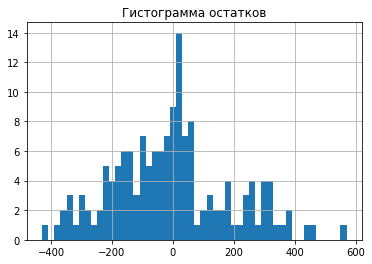

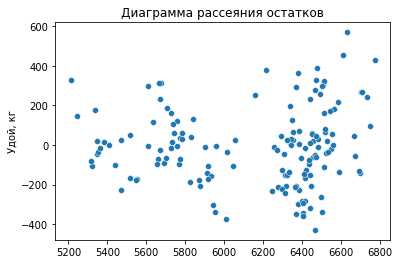

In [60]:
model_lr2.fit(x_train2,y_train2)

y_pred2 = model_lr2.predict(x_test2)
r2 = r2_score(y_test2,y_pred2)
print('r2 score',r2)
errors2 = y_test2 - y_pred2

errors2.hist(bins=50)
plt.title('Гистограмма остатков')
plt.show()

sns.scatterplot(x=y_pred2,y=errors2)
plt.title('Диаграмма рассеяния остатков')
plt.show()

По итогу обучения второй модели можно сказать, что r2 метрика осталась примерно такой же, распределение остатков стало менее смещенным в сторону. А на диаграмме рассеяния остатков дисперсия при удое больше 6000 осталась все еще слишком большой, но все равно чуть меньше чем было до этого.

Давайте обучим третью модель, в этот раз отличие будет в том, что мы добавим в таблицу новый столбец с именем папы коровы

In [64]:
df_ferma = pd.merge(df_ferma,df_dad,on='id',how='left')

In [65]:
x3 = df_ferma.drop(['Удой, кг','id','Белок,%','Жирность,%'], axis=1)
y3 = df_ferma['Удой, кг']
cat_col_names = ['Порода','Тип пастбища','Возраст','СПО','Имя Папы']
num_col_names = ['ЭКЕ квадрат','Сырой протеин, г']
x_train3,x_test3,y_train3,y_test3 = train_test_split(x3,y3,random_state=42)
encoder3 = OneHotEncoder(sparse=False,drop='first')
scaler3 = StandardScaler()
model_lr3 = LinearRegression()

x_train_ohe = encoder3.fit_transform(x_train3[cat_col_names])
x_train_scale = scaler3.fit_transform(x_train3[num_col_names])
x_train_ohe = pd.DataFrame(x_train_ohe,columns=encoder3.get_feature_names())
x_train_scale = pd.DataFrame(x_train_scale,columns=num_col_names)

x_test_ohe = encoder3.transform(x_test3[cat_col_names])
x_test_scale = scaler3.transform(x_test3[num_col_names])
x_test_ohe = pd.DataFrame(x_test_ohe,columns=encoder3.get_feature_names())
x_test_scale = pd.DataFrame(x_test_scale,columns=num_col_names)

x_train3 = x_train_scale.join(x_train_ohe)
x_test3 = x_test_scale.join(x_test_ohe)

/opt/conda/lib/python3.9/site-packages/sklearn/utils/deprecation.py:87: FutureWarning: Function get_feature_names is deprecated; get_feature_names is deprecated in 1.0 and will be removed in 1.2. Please use get_feature_names_out instead.
  warnings.warn(msg, category=FutureWarning)
/opt/conda/lib/python3.9/site-packages/sklearn/utils/deprecation.py:87: FutureWarning: Function get_feature_names is deprecated; get_feature_names is deprecated in 1.0 and will be removed in 1.2. Please use get_feature_names_out instead.
  warnings.warn(msg, category=FutureWarning)


r2 score 0.839167828082554


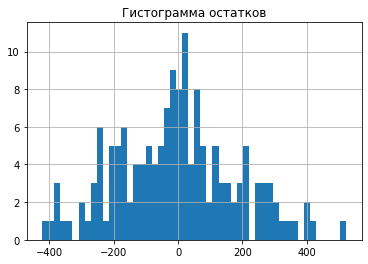

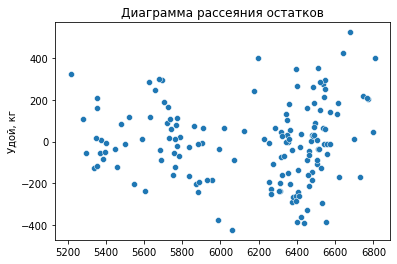

In [66]:
model_lr3.fit(x_train3,y_train3)

y_pred3 = model_lr3.predict(x_test3)
r2 = r2_score(y_test3,y_pred3)
print('r2 score',r2)
errors3 = y_test3 - y_pred3

errors3.hist(bins=50)
plt.title('Гистограмма остатков')
plt.show()

sns.scatterplot(x=y_pred3,y=errors3)
plt.title('Диаграмма рассеяния остатков')
plt.show()

На данном этапе третья модель выглядит самой лучшей, потому что r2 метрика увеличилась на одну сотую, гистограмма распределения остатков стала ближе к нулю и диаграмма рассеяния показывает, что дисперсия остатков стала меньше. Давайте проверим этот вывод с помощью других метрик

In [67]:
def metrics(true,pred):
    mae = mean_absolute_error(true,pred)
    mse = mean_squared_error(true,pred)
    rmse = np.sqrt(mse)
    print('MAE=',mae,', MSE=',mse,', RMSE=',rmse)

print('Первая модель')
metrics(y_test1,y_pred1)

quantiles=(0.025, 0.975)

lower_quantile1 = np.quantile(errors1, quantiles[0])
upper_quantile1 = np.quantile(errors1, quantiles[1])
print()
print(f"Доверительный интервал прогноза: [{lower_quantile1}, {upper_quantile1}]")
print()
print('Вторая модель')
metrics(y_test2,y_pred2)

lower_quantile2 = np.quantile(errors2, quantiles[0])
upper_quantile2 = np.quantile(errors2, quantiles[1])
print()
print(f"Доверительный интервал прогноза: [{lower_quantile2}, {upper_quantile2}]")
print()
print('Третья модель')
metrics(y_test3,y_pred3)

lower_quantile3 = np.quantile(errors3, quantiles[0])
upper_quantile3 = np.quantile(errors3, quantiles[1])
print()
print(f"Доверительный интервал прогноза: [{lower_quantile3}, {upper_quantile3}]")

Первая модель
MAE= 167.11150030955957 , MSE= 42614.56415265419 , RMSE= 206.43295316555975

Доверительный интервал прогноза: [-345.7243294224885, 436.3059485716207]

Вторая модель
MAE= 148.72840514927947 , MSE= 36671.09118960341 , RMSE= 191.49697436148543

Доверительный интервал прогноза: [-344.7167424201125, 382.2281930046861]

Третья модель
MAE= 145.3698985869189 , MSE= 34418.76515116288 , RMSE= 185.52295047018544

Доверительный интервал прогноза: [-376.4677820340652, 362.11624900343327]


Предварительные выводы подтвердились, третья модель действительно получилась самой совершенной, все метрики ошибок уменьшились, следовательно именно на третей модели следует остановиться

Пришло время применить модель на реальных данных

In [68]:
df_buy['ЭКЕ квадрат'] = df_ferma['ЭКЕ квадрат'].mean()*1.05
df_buy['Сырой протеин, г'] = df_ferma['Сырой протеин, г'].mean()*1.05
df_buy['СПО'] = 1
display(df_buy)

,Порода,Тип пастбища,порода папы_быка,Имя Папы,"Жирность,%","Текущий_уровень_белок,%",Возраст,ЭКЕ квадрат,"Сырой протеин, г",СПО,"Удой, кг"
0,Вис Бик Айдиал,Холмистое,Айдиал,Геркулес,3.58,3.076,более_2_лет,223.91962,2020.910294,1,6543.216854
1,Вис Бик Айдиал,Равнинное,Соверин,Буйный,3.54,3.081,менее_2_лет,223.91962,2020.910294,1,6244.676825
2,РефлешнСоверинг,Равнинное,Соверин,Барин,3.59,3.074,более_2_лет,223.91962,2020.910294,1,6235.462952
3,РефлешнСоверинг,Холмистое,Айдиал,Буйный,3.40,3.061,более_2_лет,223.91962,2020.910294,1,6540.102818
4,РефлешнСоверинг,Равнинное,Айдиал,Буйный,3.64,3.074,более_2_лет,223.91962,2020.910294,1,6494.316402
5,РефлешнСоверинг,Равнинное,Соверин,Геркулес,3.63,3.053,менее_2_лет,223.91962,2020.910294,1,6297.999366
6,Вис Бик Айдиал,Холмистое,Айдиал,Геркулес,3.58,3.076,более_2_лет,223.91962,2020.910294,1,6543.216854
7,Вис Бик Айдиал,Равнинное,Соверин,Буйный,3.57,3.079,более_2_лет,223.91962,2020.910294,1,6458.519283
8,РефлешнСоверинг,Равнинное,Соверин,Барин,3.59,3.074,более_2_лет,223.91962,2020.910294,1,6235.462952
9,РефлешнСоверинг,Холмистое,Айдиал,Буйный,3.40,3.079,менее_2_лет,223.91962,2020.910294,1,6329.049803


In [69]:
df_buy = df_buy.reset_index(drop=True)
df_buy = df_buy.rename(columns={'Текущая_жирность,%':'Жирность,%','Имя_папы':'Имя Папы'})

x_lin = df_buy.drop('Текущий_уровень_белок,%', axis=1)
cat_col_names = ['Порода','Тип пастбища','Возраст','СПО','Имя Папы']
num_col_names = ['ЭКЕ квадрат','Сырой протеин, г']

x_lin_ohe = encoder3.transform(df_buy[cat_col_names])
x_lin_scale = scaler3.transform(df_buy[num_col_names])
x_lin_ohe = pd.DataFrame(x_lin_ohe,columns=encoder3.get_feature_names_out())
x_lin_scale = pd.DataFrame(x_lin_scale,columns=num_col_names)

x_Udoi = x_lin_scale.join(x_lin_ohe)

df_buy['Удой, кг'] = model_lr3.predict(x_Udoi) 
display(df_buy)

/opt/conda/lib/python3.9/site-packages/sklearn/base.py:493: FutureWarning: The feature names should match those that were passed during fit. Starting version 1.2, an error will be raised.
Feature names unseen at fit time:
- Возраст_менее_2_лет
- Имя Папы_Буйный
- Имя Папы_Геркулес
- Имя Папы_Соловчик
- Порода_РефлешнСоверинг
- ...
Feature names seen at fit time, yet now missing:
- x0_РефлешнСоверинг
- x1_Холмистое
- x2_менее_2_лет
- x3_1
- x4_Буйный
- ...

  warnings.warn(message, FutureWarning)


,Порода,Тип пастбища,порода папы_быка,Имя Папы,"Жирность,%","Текущий_уровень_белок,%",Возраст,ЭКЕ квадрат,"Сырой протеин, г",СПО,"Удой, кг"
0,Вис Бик Айдиал,Холмистое,Айдиал,Геркулес,3.58,3.076,более_2_лет,223.91962,2020.910294,1,6549.266197
1,Вис Бик Айдиал,Равнинное,Соверин,Буйный,3.54,3.081,менее_2_лет,223.91962,2020.910294,1,6249.605126
2,РефлешнСоверинг,Равнинное,Соверин,Барин,3.59,3.074,более_2_лет,223.91962,2020.910294,1,6247.090941
3,РефлешнСоверинг,Холмистое,Айдиал,Буйный,3.40,3.061,более_2_лет,223.91962,2020.910294,1,6563.205230
4,РефлешнСоверинг,Равнинное,Айдиал,Буйный,3.64,3.074,более_2_лет,223.91962,2020.910294,1,6497.545142
5,РефлешнСоверинг,Равнинное,Соверин,Геркулес,3.63,3.053,менее_2_лет,223.91962,2020.910294,1,6294.951895
6,Вис Бик Айдиал,Холмистое,Айдиал,Геркулес,3.58,3.076,более_2_лет,223.91962,2020.910294,1,6549.266197
7,Вис Бик Айдиал,Равнинное,Соверин,Буйный,3.57,3.079,более_2_лет,223.91962,2020.910294,1,6467.902241
8,РефлешнСоверинг,Равнинное,Соверин,Барин,3.59,3.074,более_2_лет,223.91962,2020.910294,1,6247.090941
9,РефлешнСоверинг,Холмистое,Айдиал,Буйный,3.40,3.079,менее_2_лет,223.91962,2020.910294,1,6344.908115


По удою фермеру подойдет 19 коров из листа продажи

## Обучение модели логистической регрессии

In [70]:
clf = LogisticRegression()

Требуется предугадать значение столбца со вкусом молока. Обучим модель логистической регрессии на тренировочной выборке.

In [88]:
x4 = df_ferma.drop(['Вкус молока','id','Белок,%','Жирность,%'], axis=1)
y4 = df_ferma['Вкус молока']
cat_col_names = ['Порода','Тип пастбища','Возраст','СПО','Имя Папы']
num_col_names = ['ЭКЕ квадрат','Сырой протеин, г']

y4 = y4.apply(lambda x: 1 if x == 'вкусно' else 0)
x_train4,x_test4,y_train4,y_test4 = train_test_split(x4,y4,random_state=42)
encoder4 = OneHotEncoder(sparse=False,drop='first')
scaler4 = StandardScaler()


x_train_ohe = encoder4.fit_transform(x_train4[cat_col_names])
x_train_scale = scaler4.fit_transform(x_train4[num_col_names])
x_train_ohe = pd.DataFrame(x_train_ohe,columns=encoder4.get_feature_names())
x_train_scale = pd.DataFrame(x_train_scale,columns=num_col_names)

x_test_ohe = encoder4.transform(x_test4[cat_col_names])
x_test_scale = scaler4.transform(x_test4[num_col_names])
x_test_ohe = pd.DataFrame(x_test_ohe,columns=encoder4.get_feature_names())
x_test_scale = pd.DataFrame(x_test_scale,columns=num_col_names)

x_train4 = x_train_scale.join(x_train_ohe)
x_test4 = x_test_scale.join(x_test_ohe)

/opt/conda/lib/python3.9/site-packages/sklearn/utils/deprecation.py:87: FutureWarning: Function get_feature_names is deprecated; get_feature_names is deprecated in 1.0 and will be removed in 1.2. Please use get_feature_names_out instead.
  warnings.warn(msg, category=FutureWarning)
/opt/conda/lib/python3.9/site-packages/sklearn/utils/deprecation.py:87: FutureWarning: Function get_feature_names is deprecated; get_feature_names is deprecated in 1.0 and will be removed in 1.2. Please use get_feature_names_out instead.
  warnings.warn(msg, category=FutureWarning)


In [89]:
clf = clf.fit(x_train4,y_train4)
clf_pred = clf.predict(x_test4)
clf_proba = clf.predict_proba(x_test4)[:,1]

In [90]:
def recall(y_test,y_pred):
    cm = confusion_matrix(y_test,y_pred)
    return (cm[1][1])/(cm[0][1]+cm[1][1])

def precision(y_test,y_pred):
    cm = confusion_matrix(y_test,y_pred)
    return (cm[1][1])/(cm[1][0]+cm[1][1])

def accuracy(y_test,y_pred):
    cm = confusion_matrix(y_test,y_pred)
    return (cm[0][0]+cm[1][1])/(cm[0][0]+cm[0][1]+cm[1][1]+cm[1][0])

cm = confusion_matrix(y_test4,clf_pred)
print(cm)
print('accuracy =', accuracy(y_test4,clf_pred))
print('precision =', precision(y_test4,clf_pred))
print('recall =', recall(y_test4,clf_pred))

[[21 47]
 [14 71]]
accuracy = 0.6013071895424836
precision = 0.8352941176470589
recall = 0.6016949152542372


Так как у фермера жесткие требования нам важно, чтобы модель не давала ошибочно положительные показания, следовательно требуется сконцентрироваться на метрике precision, давайте посмотрим на результаты в зависимости от разных пороговых значений

In [91]:
thresholds = np.arange(0.0, 1.01, 0.01)
best_threshold = 0.5
opt = 0

for i in np.arange(0.5, 0.9, 0.02).round(2):
    y_pred_t = clf_proba > i
    print('порог: ', i, 'precision: ', precision_score(y_test4, y_pred_t))


порог:  0.5 precision:  0.6016949152542372
порог:  0.52 precision:  0.6160714285714286
порог:  0.54 precision:  0.6509433962264151
порог:  0.56 precision:  0.6565656565656566
порог:  0.58 precision:  0.6666666666666666
порог:  0.6 precision:  0.6867469879518072
порог:  0.62 precision:  0.6891891891891891
порог:  0.64 precision:  0.7538461538461538
порог:  0.66 precision:  0.75
порог:  0.68 precision:  0.7872340425531915
порог:  0.7 precision:  0.8292682926829268
порог:  0.72 precision:  0.8333333333333334
порог:  0.74 precision:  0.8387096774193549
порог:  0.76 precision:  0.8461538461538461
порог:  0.78 precision:  0.8888888888888888
порог:  0.8 precision:  0.9333333333333333
порог:  0.82 precision:  0.8888888888888888
порог:  0.84 precision:  1.0
порог:  0.86 precision:  1.0
порог:  0.88 precision:  1.0


Оптимальным значением порога в данном случае является 0.84

In [95]:

x_log = df_buy.drop(['Текущий_уровень_белок,%','Удой, кг','Жирность,%'], axis=1)
cat_col_names = ['Порода','Тип пастбища','Возраст','СПО','Имя Папы']
num_col_names = ['ЭКЕ квадрат','Сырой протеин, г']

x_log_ohe = encoder4.transform(df_buy[cat_col_names])
x_log_scale = scaler4.transform(df_buy[num_col_names])
x_log_ohe = pd.DataFrame(x_lin_ohe,columns=encoder4.get_feature_names_out())
x_log_scale = pd.DataFrame(x_lin_scale,columns=num_col_names)

x_Vkus = x_log_scale.join(x_log_ohe)

df_buy['Вкус молока'] = pd.Series(clf.predict_proba(x_Vkus)[:,1]).apply(lambda x: 'не вкусно' if x>=0.84 else 'вкусно')
display(df_buy)

/opt/conda/lib/python3.9/site-packages/sklearn/base.py:493: FutureWarning: The feature names should match those that were passed during fit. Starting version 1.2, an error will be raised.
Feature names unseen at fit time:
- Возраст_менее_2_лет
- Имя Папы_Буйный
- Имя Папы_Геркулес
- Имя Папы_Соловчик
- Порода_РефлешнСоверинг
- ...
Feature names seen at fit time, yet now missing:
- x0_РефлешнСоверинг
- x1_Холмистое
- x2_менее_2_лет
- x3_1
- x4_Буйный
- ...

  warnings.warn(message, FutureWarning)


,Порода,Тип пастбища,порода папы_быка,Имя Папы,"Жирность,%","Текущий_уровень_белок,%",Возраст,ЭКЕ квадрат,"Сырой протеин, г",СПО,"Удой, кг",Вкус молока
0,Вис Бик Айдиал,Холмистое,Айдиал,Геркулес,3.58,3.076,более_2_лет,223.91962,2020.910294,1,6549.266197,вкусно
1,Вис Бик Айдиал,Равнинное,Соверин,Буйный,3.54,3.081,менее_2_лет,223.91962,2020.910294,1,6249.605126,вкусно
2,РефлешнСоверинг,Равнинное,Соверин,Барин,3.59,3.074,более_2_лет,223.91962,2020.910294,1,6247.090941,вкусно
3,РефлешнСоверинг,Холмистое,Айдиал,Буйный,3.40,3.061,более_2_лет,223.91962,2020.910294,1,6563.205230,вкусно
4,РефлешнСоверинг,Равнинное,Айдиал,Буйный,3.64,3.074,более_2_лет,223.91962,2020.910294,1,6497.545142,вкусно
5,РефлешнСоверинг,Равнинное,Соверин,Геркулес,3.63,3.053,менее_2_лет,223.91962,2020.910294,1,6294.951895,вкусно
6,Вис Бик Айдиал,Холмистое,Айдиал,Геркулес,3.58,3.076,более_2_лет,223.91962,2020.910294,1,6549.266197,вкусно
7,Вис Бик Айдиал,Равнинное,Соверин,Буйный,3.57,3.079,более_2_лет,223.91962,2020.910294,1,6467.902241,вкусно
8,РефлешнСоверинг,Равнинное,Соверин,Барин,3.59,3.074,более_2_лет,223.91962,2020.910294,1,6247.090941,вкусно
9,РефлешнСоверинг,Холмистое,Айдиал,Буйный,3.40,3.079,менее_2_лет,223.91962,2020.910294,1,6344.908115,вкусно


## Итоговые выводы

По итогу после применения моделей на реальных данных можно сказать, что из стада можно брать всех коров, все они соответсвуют по количеству удоя и вкусу молока

У фермера очень строгие критерии и он хочет покупать коров только если они соответствуют им, следовательно нам нужно минимизировать ложноположительные ошибки, поэтому надо заострить внимание на метрике precision. В качестве порогового значения мы выбрали 0.84 так как при нем precision равна 1, но при этом и метрика recall не равна своему минимальному значению

Для улучшение моделей требуется больше признаков с линейной зависимостью с целевыми переменными. Модель линейной регрессии имеет низкую точность из за недостатка таких, а модель линейной регрессии все еще имеет большой разлет ошибок при больших цифрах удоя